<a href="https://colab.research.google.com/github/Ali010304/metodos-numericos-1/blob/main/M%C3%A9todo_en_Newton_Raphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Método de Newton-Raphson

Nos encontramos quizás con el mejor método para poder encontrar la raíz de una función en un intervalo dado.

El Método de Newton-Raphson es un algoritmo iterativo matemático, a diferencia de los otros dos métodos que acotan la búsqueda en intervalos cada vez más pequeños, este método utiliza especificamente sus rectas tangentes para aproximarse a la silución de manera más rápida y directa.

De otra manera, la recta tangente a la curva en el punto $(x_n,f(x_n))$ tiene como derivada en ese punto es $f´(x_n)$, al utilizar la la ecuación **punto pendiente** se obtienen la fórmula fundamental de este método:

$$x_p=x_n- \frac{f(x_n)}{f´(x_n)}$$

El método resulta sencillo de aplicar si se siguen los pasos correctamente, y es la siguiente:
- Se define la función $f(x)$ y su derivada $f´(x)$.

- Se toma un valor inicial $p_0$, que es una aproximación intuitiva de la raíz que se desea obtener.

- Aplicando la fórmula dada se obtiene una aproximación de la raíz, esa nueva aproximación será el nuevo punto a evaluar hasta que la evaluación converge a un valor específico.

- El procedimiento se detiene hasta que la diferencia entre dos iteraciones consecuitvas sea menor a la tolerancia establecida previamente, es decir:
$$|e|=|x_n - x_p| \implies |e| \leq TOL$$

Donde
- $x_n$ es la última iteración realizada.
- $x_p$ es la iteración anterior a $x_n$.
- $TOL$ es la tolerancia requerida para comprobar la válidez del procedimiento, de otra manera, es la cantidad de décimales de exactitud.




# Ejemplo

Hallar la raíz aproximada de la ecuación $f(x)=cos(x)-x$ mediante el método de Newton-Raphson con una toleracncia de 0.00001.

Para empezar, calculemos el intervalo donde trabajaremos, tomemos el intervalo [0,1], entonces evaluando:

- $f(0)=cos(0)-0 \implies 1-0=0$
- $f(1)=cos(1)+1 \implies 0.5403-1=-0.4597$

Como ambas evaluaciones tienen signos opuestos, entonces por el T.V.I. aseguramos que hay una raíz entre 0 y 1.

Entonces:
- Intervalo=[0,1]
- $f(x)= cos(x)-x$
- $f´(x)= -sen(x) -1 \implies sen(x)+1$
- Método Newton-Raphson:
$$x_p=x_n- \frac{f(x_n)}{f´(x_n)}=x_n+\frac{cos(x_n)-x_n}{sen(x_n)+1}$$


- **Iteración 1**

Partiendo de $x_n=1$:


$$x_1=1+\frac{cos(1)-1}{sen(1)+1} \implies 1+\frac{-0.45970}{1.84197}= 1-0.24964$$
\
$$x_1=0.75036$$


- **Iteración 2**

Ahora partimos de $x_2=0.7536$:

$$x_1=0.75036+\frac{cos(0.75036)-0.75036}{sen(0.7536)+1}$$

\
$$=0.75036+\frac{-0.01866}{1.68199}\implies 0.75036-0.01109$$

\
$$\therefore x_p=0.73927$$

- **Iteración 3**

$$x_p=0.73927-\frac{cos(0.73927)-0.73927}{sen(0.73927)+1}$$

\
$$=0.73927-\frac{0.00014}{1.67361}\implies 0.73927-0.00008$$
\
$$\therefore x_p=0.73908$$

De esta manera, obtenemos una excelente aproximación con $n=3$, aunque se puede obtener una aproximacion más exacta al evaluar $p_3$ y $p_4$, aunque en nuestro caso lo dejareos así, ya que la tolerancia solicitada es de 0.00001.















#Código para la evaluación del Método de Newton-Raphson

El ejemplo anterior hecho paso a paso nos muestra como este método puede dar aproximaciones precisas con muy pocas iteraciones, aunque en este caso las iteraciones fueron pocas, puede ocurrir que no lo sea así. De esta manera, en la parte inferior a este texto se muestra un código que ayuda a generar las iteraciones sin necesidad de calcular cada operación a mano, evitandonos aproximaciones cercanas y pudiendo obtener una aproximación más exacta.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

Bibliotecas importadas para realizar cálculos matematicos

In [ ]:
def f(x):
  return np.cos(x) - x

Se define la función con la que se desea trabajar

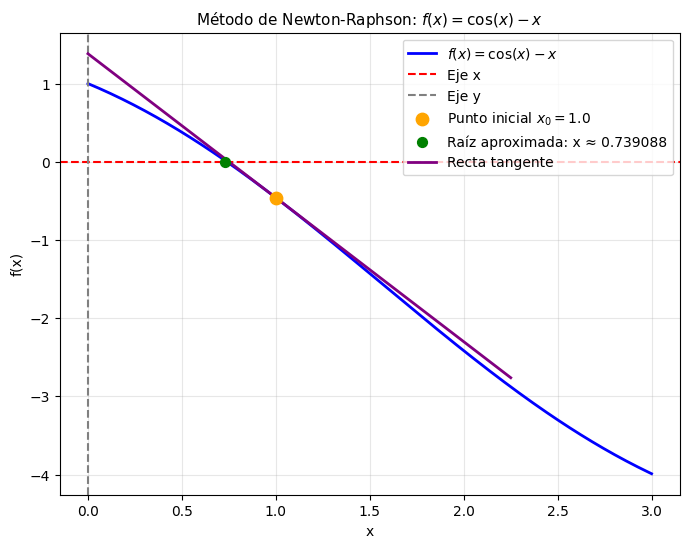

In [ ]:
def df(x):
    return -np.sin(x) - 1

plt.figure(figsize=(8, 6))

x = np.linspace(0, 3, 200)
plt.plot(x, f(x), label=r"$f(x) = \cos(x) - x$", color="blue", linewidth=2)

plt.axhline(y=0, color="red", linestyle="--", label="Eje x")
plt.axvline(x=0, color="gray", linestyle="--", label="Eje y")


x0 = 1.0
fx0 = f(x0)
dfx0 = df(x0)
x1 = x0 - fx0 / dfx0


plt.scatter(
    [x0],
    [fx0],
    color="orange",
    s=80,
    zorder=5,
    label=f"Punto inicial $x_0 = {x0}$",
)

plt.scatter(
    [0.729088],
    [0],
    color="green",
    s=50,
    zorder=5,
    label=f"Raíz aproximada: x ≈ {0.739088:.6f}",
)

x_tangente = np.linspace(x0 - 1, x1 + 1.5, 100)
y_tangente = fx0 + dfx0 * (x_tangente - x0)


plt.plot(
    x_tangente,
    y_tangente,
    color="purple",
    linestyle="-",
    linewidth=2,
    label="Recta tangente",
)


plt.title(
    r"Método de Newton-Raphson: $f(x) = \cos(x) - x$",
    fontsize=11,
)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.show()

Se realiza la gráfica de la función paa poder comprender mejor el problema.

In [ ]:
def newton(p0,tol):
  tol= 0.0001
  error=100
  Lerror=[]
  Lp_i=[]

  while error> tol:
    p1=p0-f(p0)/f(p0+1)
    error=np.abs(p1-p0)
    Lerror.append(error)
    Lp_i.append(p1)
    p0=p1
  return  Lp_i,Lerror

En esta parte ocurre la magia, con este pequeño codigo se realiza el cálculo de la raíz mediante el métdo de Newton-Raphso,

In [ ]:
import pandas as pd
pd.DataFrame(newton(1,0.00001)).T

,0,1
0,0.809739,0.190261
1,0.751075,0.058665
2,0.740652,0.010422
3,0.739278,0.001374
4,0.739109,0.000170
5,0.739088,0.000021


Pequeña tabla que muestra las iteraciones necesarias para poder encontrar la raíz de la función definida anteriormente.
Y es aquí donde podemos comprobar la efectividad del códigp  pues la raíz es $x_p=0.739088$